# Bab 4 — Building Models with Distance Metrics and Nearest Neighbors

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025)

---

| No | Resep | Isi |
|----|-------|-----|
| 1 | Memahami KNN | KNN dasar pada dataset Iris |
| 2 | Ikhtisar metrik jarak | Euclidean vs Manhattan vs Minkowski pada dua dataset sintetis |
| 3 | Tuning hyperparameter | `GridSearchCV` untuk `n_neighbors`, `weights`, `metric` |
| 4 | Evaluasi performa | cross-validation, learning curve, confusion matrix, classification report |
| 5 | Latihan | KNN pada Breast Cancer, grid search & evaluasi pada data sintetis |

## Resep 1 — Memahami k-Nearest Neighbors

### Teori
KNN adalah algoritma **non-parametrik** dan **lazy learner**:
- *Non-parametrik*: tidak mengasumsikan bentuk fungsi tertentu (tidak ada koefisien yang dipelajari).
- *Lazy*: `fit()` hanya menyimpan data latih (dan membangun struktur indeks seperti KD-Tree/Ball-Tree). Semua komputasi terjadi saat `predict()`.

Untuk titik baru $\mathbf{x}$, misalkan $\mathcal{N}_k(\mathbf{x})$ adalah himpunan $k$ titik latih terdekat.

- **Klasifikasi** (voting mayoritas):
$$\hat y = \arg\max_{c} \sum_{i \in \mathcal{N}_k(\mathbf{x})} \mathbb{1}[y_i = c], \qquad \hat P(Y=c\mid\mathbf{x}) = \frac{1}{k}\sum_{i\in\mathcal{N}_k}\mathbb{1}[y_i=c]$$
- **Regresi** (rata-rata): $\hat y = \frac{1}{k}\sum_{i \in \mathcal{N}_k(\mathbf{x})} y_i$
- **Pembobotan jarak** (`weights='distance'`): tetangga yang lebih dekat diberi bobot $w_i = 1/d(\mathbf{x}, \mathbf{x}_i)$.

**Bias–variance trade-off pada $k$:**
- $k$ kecil (misal 1) → batas keputusan sangat berliku, mengikuti noise → **varians tinggi** (overfitting).
- $k$ besar → batas keputusan halus, detail lokal hilang → **bias tinggi** (underfitting). Jika $k = n$, model selalu memprediksi kelas mayoritas.

Untuk klasifikasi biner, $k$ ganjil menghindari seri.

**Kompleksitas:** prediksi naif $O(n \cdot p)$ per titik; KD-Tree/Ball-Tree mempercepat pada dimensi rendah. Pada dimensi tinggi, KNN menderita *curse of dimensionality*: jarak ke tetangga terdekat dan terjauh menjadi hampir sama sehingga "kedekatan" kehilangan makna.

### Persiapan — dataset Iris

In [ ]:
# Load libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Load the iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2024
)

In [ ]:
# Load libraries
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Create and train a basic KNN model
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Make predictions
y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9333333333333333


**Interpretasi.** Dengan $k=3$ dan tanpa tuning, KNN sudah mencapai akurasi yang sangat tinggi pada Iris. Dataset ini berdimensi rendah (4 fitur), skalanya mirip (semua dalam cm), dan kelas-kelasnya membentuk kelompok yang jelas — kondisi ideal untuk KNN. Iris tidak di-*scale* di sini karena keempat fitur sudah bersatuan sama; pada data dengan satuan berbeda, scaling **wajib** untuk KNN.

## Resep 2 — Ikhtisar Metrik Jarak

### Teori
Metrik jarak $d$ harus memenuhi: $d(\mathbf a,\mathbf b)\ge 0$, $d(\mathbf a,\mathbf b)=0 \iff \mathbf a=\mathbf b$, simetri, dan ketaksamaan segitiga. Keluarga **Minkowski** dengan parameter $q$:

$$d_q(\mathbf{a}, \mathbf{b}) = \left(\sum_{j=1}^{p} |a_j - b_j|^q\right)^{1/q}$$

| Metrik | $q$ | Rumus | Bentuk "bola" satuan (2D) | Karakter |
|---|---|---|---|---|
| Manhattan / L1 / *city block* | 1 | $\sum_j \lvert a_j-b_j\rvert$ | belah ketupat | kurang sensitif terhadap satu selisih besar (outlier) |
| Euclidean / L2 | 2 | $\sqrt{\sum_j (a_j-b_j)^2}$ | lingkaran | jarak "garis lurus", invarian terhadap rotasi |
| Chebyshev / L∞ | ∞ | $\max_j \lvert a_j-b_j\rvert$ | persegi | hanya selisih terbesar yang menentukan |

Di scikit-learn, `metric='minkowski'` memakai default `p=2`, sehingga **identik dengan Euclidean**. Itu sebabnya hasil `euclidean` dan `minkowski` di bawah selalu sama.

### Persiapan — dua dataset sintetis
- **Noisy circles**: dua lingkaran konsentris dengan noise tinggi (struktur radial).
- **Checkerboard**: grid titik yang diberi label seperti papan catur (batas kelas sejajar sumbu).

Catatan: `make_circles` pada kode buku dipanggil tanpa `random_state`, sehingga data (dan akurasi) bisa berubah cukup jauh setiap kali dijalankan. Agar hasil notebook ini *reproducible*, seed global NumPy diset terlebih dulu tanpa mengubah kode buku.

In [ ]:
import numpy as np
np.random.seed(2024)  # tambahan: membuat make_circles() reproducible

In [ ]:
# Load libraries
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

# Create two synthetic datasets that highlight metric differences
n_samples = 300

# Circular dataset with high noise (Euclidean distance should work better)
X_circles, y_circles = make_circles(n_samples=n_samples, noise=0.3, factor=0.3)
X_circles_train, X_circles_test, y_circles_train, y_circles_test = train_test_split(
    X_circles, y_circles, test_size=0.2, random_state=2024
)

# Checkerboard pattern dataset (Manhattan distance should work better)
x = np.linspace(0, 4, int(np.sqrt(n_samples)))
y = np.linspace(0, 4, int(np.sqrt(n_samples)))
xx, yy = np.meshgrid(x, y)
X_moons = np.column_stack((xx.ravel(), yy.ravel()))
y_moons = np.mod(np.floor(xx.ravel()) + np.floor(yy.ravel()), 2)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.2, random_state=2024
)

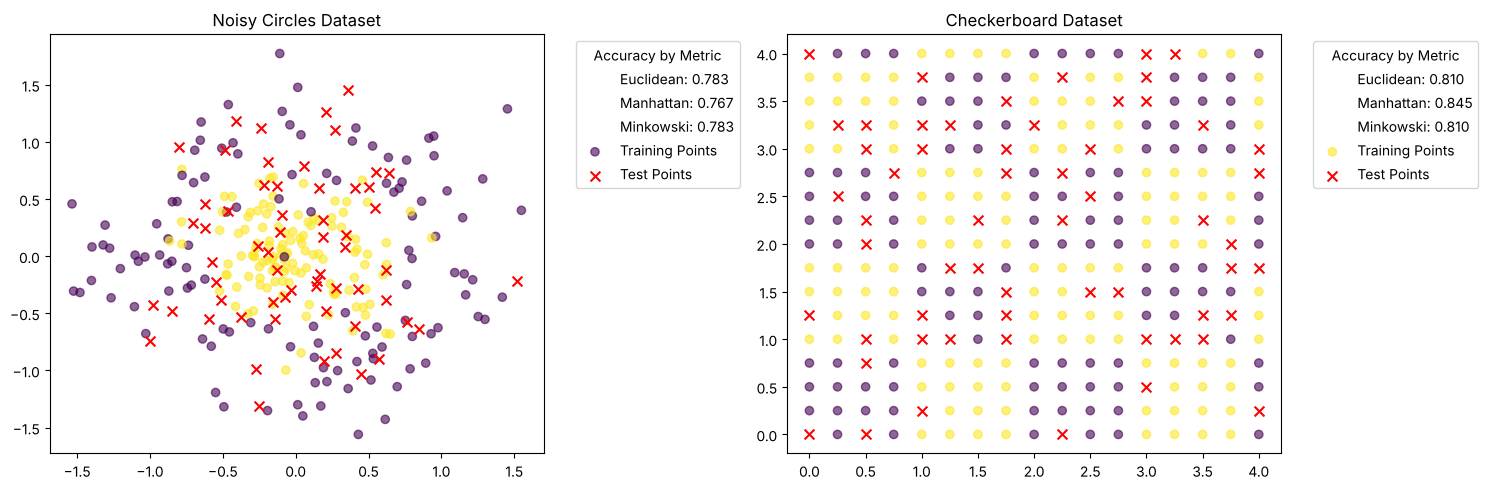

In [ ]:
# Compare different distance metrics on both datasets
metrics = ['euclidean', 'manhattan', 'minkowski']
results = {'circles': {}, 'moons': {}}

for metric in metrics:
    # Test on "circles" dataset
    knn_circles = KNeighborsClassifier(n_neighbors=3, metric=metric)
    knn_circles.fit(X_circles_train, y_circles_train)
    y_pred_circles = knn_circles.predict(X_circles_test)
    results['circles'][metric] = accuracy_score(y_circles_test, y_pred_circles)

    # Test on "moons" dataset
    knn_moons = KNeighborsClassifier(n_neighbors=3, metric=metric)
    knn_moons.fit(X_moons_train, y_moons_train)
    y_pred_moons = knn_moons.predict(X_moons_test)
    results['moons'][metric] = accuracy_score(y_moons_test, y_pred_moons)

# Set up plot specs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot circles dataset
scatter1_train = ax1.scatter(X_circles_train[:, 0], X_circles_train[:, 1], c=y_circles_train, cmap='viridis', alpha=0.6, label='Training Points')
scatter1_test = ax1.scatter(X_circles_test[:, 0], X_circles_test[:, 1], color='red', marker='x', s=50, label='Test Points')
ax1.set_title('Noisy Circles Dataset')

# Create dummy lines for legend
lines1 = [plt.Line2D([0], [0], color='white') for _ in metrics]
legend_text1 = [
    f"Euclidean: {results['circles']['euclidean']:.3f}",
    f"Manhattan: {results['circles']['manhattan']:.3f}",
    f"Minkowski: {results['circles']['minkowski']:.3f}"
]
ax1.legend(lines1 + [scatter1_train, scatter1_test], legend_text1 + ['Training Points', 'Test Points'],
          title='Accuracy by Metric', bbox_to_anchor=(1.05, 1), loc='upper left')

# Plot moons dataset
scatter2_train = ax2.scatter(X_moons_train[:, 0], X_moons_train[:, 1], c=y_moons_train, cmap='viridis', alpha=0.6, label='Training Points')
scatter2_test = ax2.scatter(X_moons_test[:, 0], X_moons_test[:, 1], color='red', marker='x', s=50, label='Test Points')
ax2.set_title('Checkerboard Dataset')

# Create dummy lines for legend
lines2 = [plt.Line2D([0], [0], color='white') for _ in metrics]
legend_text2 = [
    f"Euclidean: {results['moons']['euclidean']:.3f}",
    f"Manhattan: {results['moons']['manhattan']:.3f}",
    f"Minkowski: {results['moons']['minkowski']:.3f}"
]
ax2.legend(lines2 + [scatter2_train, scatter2_test], legend_text2 + ['Training Points', 'Test Points'],
          title='Accuracy by Metric', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
# Akurasi per metrik dalam bentuk tabel
import pandas as pd
display(pd.DataFrame(results).T.round(3))

,euclidean,manhattan,minkowski
circles,0.783,0.767,0.783
moons,0.810,0.845,0.810


**Interpretasi.**
- Euclidean dan Minkowski selalu memberi akurasi yang **identik**, karena Minkowski default ($p=2$) memang Euclidean.
- Pada dataset **checkerboard**, Manhattan unggul (0,845 vs 0,810). Kelas berubah di garis-garis vertikal dan horizontal (batas sejajar sumbu), dan titik-titik berada di grid teratur. "Bola" Manhattan yang berbentuk belah ketupat dan selisih per-sumbu yang dijumlahkan lebih cocok dengan struktur sejajar sumbu ini, dan pada grid dengan banyak jarak yang sama, kedua metrik memilih himpunan tetangga yang berbeda.
- Pada dataset **noisy circles**, Euclidean sedikit unggul (0,783 vs 0,767). Struktur datanya radial (lingkaran), sehingga jarak "garis lurus" yang invarian terhadap rotasi lebih alami. Selisihnya hanya 1 titik dari 60 dan noise yang tinggi membuat kedua kelas tumpang tindih, sehingga akurasi semua metrik relatif rendah.
- Kedua hasil ini sesuai dengan hipotesis yang ditulis di komentar kode buku.

Pelajaran: **tidak ada metrik yang selalu terbaik**; metrik adalah hyperparameter yang perlu diuji untuk data spesifik.

## Resep 3 — Tuning Hyperparameter KNN dengan Grid Search

### Teori
**Grid search** mencoba **semua** kombinasi hyperparameter pada grid yang ditentukan. Di sini: 5 nilai `n_neighbors` × 2 `weights` × 2 `metric` = **20 kombinasi**. Setiap kombinasi dievaluasi dengan **5-fold cross-validation**, jadi total 100 kali pelatihan. Kombinasi dengan rata-rata skor CV tertinggi dipilih, lalu model dilatih ulang pada seluruh data latih (`refit=True`) dan tersedia sebagai `best_estimator_`.

Hal penting: grid search hanya memakai **data latih**. Data uji tetap disimpan untuk evaluasi akhir yang jujur. Jika jumlah kombinasi sangat besar, `RandomizedSearchCV` (mengambil sampel acak dari ruang hyperparameter) biasanya lebih efisien.

In [ ]:
# Load libraries
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

# Create KNN classifier
knn = KNeighborsClassifier()

# Define parameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Create grid search
grid_search = GridSearchCV(
    knn, param_grid, cv=5, scoring='accuracy'
)

# Fit grid search
grid_search.fit(X_train, y_train)

# Print best parameters and score
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best cross-validation score: 0.9916666666666668


In [ ]:
# Melihat 8 kombinasi terbaik dari seluruh 20 kombinasi
import pandas as pd
cv_res = pd.DataFrame(grid_search.cv_results_)
cols = ['param_n_neighbors', 'param_weights', 'param_metric', 'mean_test_score', 'std_test_score', 'rank_test_score']
display(cv_res[cols].sort_values('rank_test_score').head(8))

,param_n_neighbors,param_weights,param_metric,mean_test_score,std_test_score,rank_test_score
6,9,uniform,euclidean,0.991667,0.016667,1
7,9,distance,euclidean,0.991667,0.016667,1
0,3,uniform,euclidean,0.983333,0.020412,3
1,3,distance,euclidean,0.983333,0.020412,3
3,5,distance,euclidean,0.983333,0.020412,3
2,5,uniform,euclidean,0.983333,0.020412,3
5,7,distance,euclidean,0.983333,0.020412,3
4,7,uniform,euclidean,0.983333,0.020412,3


**Interpretasi.** Pada Iris banyak kombinasi memiliki skor CV yang sama atau hampir sama (lihat kolom `rank_test_score` yang sering seri). Artinya, untuk dataset sederhana ini pilihan hyperparameter tidak terlalu kritis — jika beberapa kombinasi seri, `GridSearchCV` memilih yang muncul pertama di grid. Kolom `std_test_score` menunjukkan seberapa stabil skor antar-fold; dengan hanya ±24 sampel per fold validasi, satu kesalahan prediksi sudah menggeser skor sekitar 4 poin persentase.

## Resep 4 — Mengevaluasi Performa KNN

### Teori
- **Cross-validation score**: rata-rata dan simpangan baku akurasi pada $k$ fold.
- **Learning curve**: skor latih dan skor validasi sebagai fungsi ukuran data latih.
  - Kedua kurva tinggi dan berdekatan → model baik.
  - Skor latih jauh di atas skor validasi → **overfitting** (varians tinggi); menambah data biasanya membantu.
  - Kedua kurva rendah → **underfitting** (bias tinggi); butuh model/fitur yang lebih kaya.
- **Confusion matrix** $\mathbf{C}$: $C_{ij}$ = jumlah sampel kelas sebenarnya $i$ yang diprediksi sebagai kelas $j$. Diagonal = prediksi benar.
- **Metrik per kelas** (TP = *true positive*, FP = *false positive*, FN = *false negative*):
$$\text{Precision} = \frac{TP}{TP+FP}, \qquad \text{Recall} = \frac{TP}{TP+FN}, \qquad F_1 = 2\cdot\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$
  Precision menjawab "dari yang diprediksi kelas $c$, berapa yang benar?"; recall menjawab "dari semua kelas $c$ sebenarnya, berapa yang tertangkap?". $F_1$ adalah rata-rata harmonik keduanya.
- **Macro avg** = rata-rata biasa antar kelas; **weighted avg** = rata-rata yang dibobot jumlah sampel (*support*) per kelas.

In [ ]:
# Load libraries
from sklearn.model_selection import learning_curve, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

Cross-validation scores: [0.95833333 1.         1.         1.         1.        ]
Mean CV score: 0.9916666666666668
Standard deviation: 0.016666666666666653


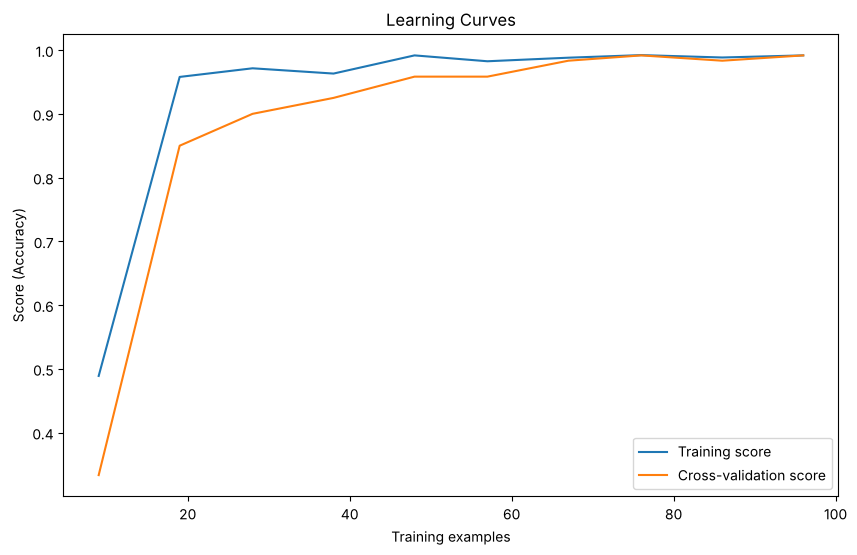

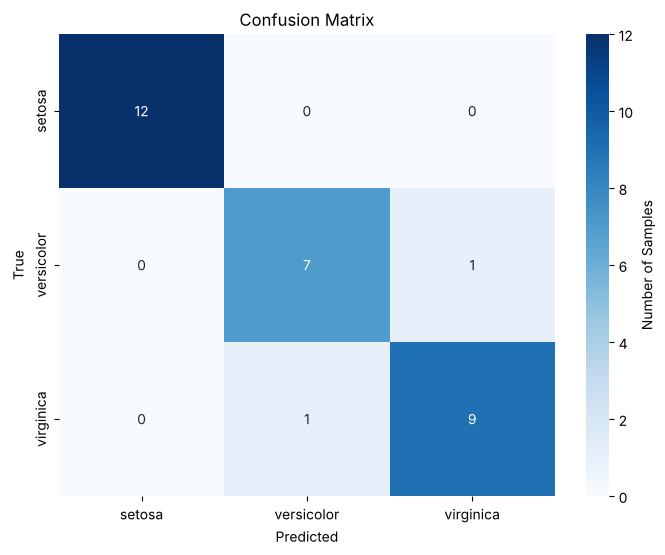


Classification Report:


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,12
versicolor,0.875,0.875,0.875,8
virginica,0.900,0.900,0.900,10
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.925,0.925,30
weighted avg,0.933,0.933,0.933,30


In [ ]:
# Get cross-validation scores
cv_scores = cross_val_score(grid_search.best_estimator_, X_train, y_train, cv=5)
print("Cross-validation scores:", cv_scores)
print("Mean CV score:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

# Generate learning curves
train_sizes, train_scores, test_scores = learning_curve(
    grid_search.best_estimator_, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5
)

# Plot learning curves
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, np.mean(train_scores, axis=1), label='Training score')
plt.plot(train_sizes, np.mean(test_scores, axis=1), label='Cross-validation score')
plt.xlabel('Training examples')
plt.ylabel('Score (Accuracy)')
plt.legend(loc='best')
plt.title('Learning Curves')
plt.show()

# Make predictions on test set
y_pred = grid_search.best_estimator_.predict(X_test)

# Get class names from iris dataset
class_names = iris.target_names

# Generate and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Get classification report as a dict
report_dict = classification_report(y_test, y_pred,
                                  target_names=class_names,
                                  output_dict=True)

# Create a DataFrame for better visualization
report_df = pd.DataFrame(report_dict).transpose()

# Style the DataFrame
styled_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print("\nClassification Report:")
display(styled_df)

**Interpretasi.**
- **Skor CV** per fold tinggi, dengan simpangan baku yang kecil → model stabil.
- **Learning curve**: skor latih tetap tinggi, sedangkan skor validasi naik cepat ketika data latih bertambah lalu mendatar. Setelah titik itu, menambah data tidak banyak meningkatkan performa. Untuk KNN dengan `weights='distance'`, skor latih bisa bernilai 1,0 karena setiap titik latih adalah "tetangga" dirinya sendiri dengan jarak 0 — ini sifat algoritma, bukan tanda pasti overfitting.
- **Confusion matrix**: model terbaik (k = 9, Euclidean, uniform) benar pada 28 dari 30 sampel uji (akurasi 0,933). Semua 12 *setosa* benar karena kelas ini terpisah jelas. Dua kesalahan terjadi antara *versicolor* dan *virginica* (masing-masing satu sampel tertukar), yang ukuran kelopaknya memang saling tumpang tindih.
- Perhatikan bahwa skor CV (≈0,99) lebih tinggi daripada akurasi uji (0,933). Dengan data uji hanya 30 sampel, setiap kesalahan bernilai 3,3 poin persentase, sehingga perbedaan ini masih dalam batas variasi wajar.
- Catatan tentang classification report: kelas *setosa* mendapat skor sempurna karena memang mudah dipisahkan, bukan otomatis tanda overfitting — overfitting dinilai dari selisih performa latih vs data yang belum dilihat.

## Latihan Praktik

### Latihan 1 — KNN untuk klasifikasi biner (Breast Cancer Wisconsin)
569 sampel tumor dengan 30 fitur hasil pengukuran citra inti sel; target 0 = ganas (*malignant*), 1 = jinak (*benign*). Fitur-fiturnya memiliki skala yang sangat berbeda (misalnya `mean area` ratusan hingga ribuan, `mean smoothness` sekitar 0,1), sehingga **StandardScaler** wajib dipakai sebelum KNN.

In [ ]:
# Load libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Load the Dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Preprocess the Data
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create and Train the KNN Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Make Predictions
y_pred = knn.predict(X_test_scaled)

# Evaluate Performance
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.947

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        43
           1       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



In [ ]:
# Apakah scaling benar-benar membantu? Bandingkan pada split yang sama...
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print('Split tunggal  -> TANPA scaling: %.3f | DENGAN scaling: %.3f'
      % (accuracy_score(y_test, knn_raw.predict(X_test)), accuracy_score(y_test, y_pred)))

# ...lalu dengan 10-fold stratified cross-validation (estimasi yang lebih andal)
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
s_raw = cross_val_score(KNeighborsClassifier(n_neighbors=5), X, y, cv=cv10)
s_std = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)), X, y, cv=cv10)
print('10-fold CV     -> TANPA scaling: %.3f ± %.3f | DENGAN scaling: %.3f ± %.3f'
      % (s_raw.mean(), s_raw.std(), s_std.mean(), s_std.std()))

Split tunggal  -> TANPA scaling: 0.956 | DENGAN scaling: 0.947
10-fold CV     -> TANPA scaling: 0.935 ± 0.029 | DENGAN scaling: 0.970 ± 0.018


**Interpretasi.** Hasil ini memberi pelajaran penting. Pada **split tunggal** buku (`random_state=42`), model **tanpa** scaling justru sedikit lebih akurat (0,956 vs 0,947) — selisihnya hanya 1 sampel dari 114. Namun dengan **10-fold cross-validation** pada seluruh data, scaling jelas lebih baik (≈0,935 → ≈0,970) dan juga lebih stabil (std lebih kecil).

Penjelasan teorinya: tanpa scaling, jarak Euclidean hampir sepenuhnya ditentukan oleh fitur berskala besar (`area`, `perimeter`), sehingga fitur berskala kecil yang informatif nyaris diabaikan. Kesimpulan dari satu split acak bisa menyesatkan; gunakan cross-validation saat membandingkan dua pendekatan. Pada konteks medis, perhatikan juga **recall kelas 0 (ganas)**: tumor ganas yang lolos terdeteksi sebagai jinak (false negative) jauh lebih berbahaya daripada sebaliknya.

### Latihan 2 — Grid search pada data sintetis 3 kelas

In [ ]:
# Load libraries
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Load a different dataset
X, y = make_classification(n_samples=1000, n_features=20, n_informative=15,
                         n_redundant=5, n_classes=3, random_state=42)

# Preprocess the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Set up grid search:
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
knn = KNeighborsClassifier()
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')

# Fit grid search
grid_search.fit(X_train_scaled, y_train)

# Evaluate best model
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)
y_pred = grid_search.predict(X_test_scaled)
print("\nTest Set Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best cross-validation score: 0.8574999999999999

Test Set Performance:
Accuracy: 0.88

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.86      0.89        70
           1       0.91      0.96      0.93        73
           2       0.79      0.81      0.80        57

    accuracy                           0.88       200
   macro avg       0.88      0.87      0.87       200
weighted avg       0.88      0.88      0.88       200



**Interpretasi.** Grid search memilih k = 9, Euclidean, uniform dengan skor CV 0,857, sedangkan akurasi uji 0,880. Pada data sintetis dengan 20 fitur (15 informatif), performa lebih rendah dibanding Iris. Data ini lebih sulit karena dimensinya lebih tinggi dan kelas-kelasnya dibuat saling tumpang tindih. Skor CV terbaik dan akurasi data uji seharusnya berdekatan; jika akurasi uji jauh lebih rendah, itu tanda grid search "overfit" terhadap fold CV.

### Latihan 3 — Evaluasi lengkap KNN

In [ ]:
# Load libraries
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the Dataset
# Create a synthetic dataset with 3 classes and some informative/redundant features
X, y = make_classification(n_samples=1000,
                         n_features=15,
                         n_informative=10,
                         n_redundant=5,
                         n_classes=3,
                         n_clusters_per_class=2,
                         random_state=42)

# Preprocess the Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create and Train the KNN Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Make Predictions
y_pred = knn.predict(X_test_scaled)

# Evaluate Performance
print("Model Performance Evaluation")
print("-" * 30)
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.3f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Performance Evaluation
------------------------------
Accuracy Score: 0.850

Confusion Matrix:
[[56  6  6]
 [ 4 56  5]
 [ 6  3 58]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.82      0.84        68
           1       0.86      0.86      0.86        65
           2       0.84      0.87      0.85        67

    accuracy                           0.85       200
   macro avg       0.85      0.85      0.85       200
weighted avg       0.85      0.85      0.85       200



**Interpretasi.** Akurasi 0,850 dengan k = 5. Confusion matrix 3×3 menunjukkan diagonal 56, 56, 58 (prediksi benar) dan kesalahan yang tersebar cukup merata di semua pasangan kelas (3–6 sampel per sel). Precision dan recall setiap kelas berada di kisaran 0,82–0,87, jadi tidak ada satu kelas yang jauh lebih sulit daripada yang lain. Karena dataset seimbang (≈1/3 per kelas), akurasi di sini cukup representatif; pada data tidak seimbang, perhatikan precision/recall per kelas.

## Kesimpulan Bab 4

- KNN adalah model non-parametrik yang menyimpan data latih dan memprediksi melalui voting/rata-rata $k$ tetangga terdekat.
- **$k$** mengatur bias–variance: kecil → overfitting, besar → underfitting. Pilih dengan cross-validation.
- **Metrik jarak** adalah hyperparameter: Euclidean (L2), Manhattan (L1), Minkowski ($p=2$ = Euclidean).
- **Scaling penting** untuk KNN bila fitur berbeda satuan; pada Breast Cancer, 10-fold CV menunjukkan kenaikan akurasi ≈0,935 → ≈0,970 (walau satu split tunggal bisa memberi kesan sebaliknya).
- `GridSearchCV` + cross-validation memilih hyperparameter tanpa menyentuh data uji.
- Evaluasi menyeluruh = CV score + learning curve + confusion matrix + precision/recall/F1.